# Serie trigonométrica onda cuadrada sympy

##### STF de $x(t) = 0$ si  $-T/2\leq t \leq -T/4$, $x(t) = I_0$ si $ -T/4 < t < T/4$ y $x(t) = 0$ si $ T/4 \leq t \leq T/2$

In [1]:
import sympy as sym
from sympy import*

In [2]:
# variable y datos

t = symbols("t")
n = symbols("n", int=True, positive=True)
T = symbols("T", int=True, positive=True)   #ingrese periodo
I0 = symbols("I0", positive=True)      
m = 7                                       # ingreses número de componente

# construya la función por partes
ft = sym.Piecewise((0, t < -T/4),
                   (I0, t < T/4),
                   (0,True))
#frecuencia angular
w = 2*pi/T  

In [3]:
# Componente dc a0/2 (llamado aqui a0)
a0 = (1/T*integrate(ft, (t, -T/2, T/2)))
a0

I0/2

In [4]:
# Coeficientes an
an = (2/T)*integrate(ft*cos(w*n*t), (t, -T/2, T/2))
simplify(an)

2*I0*sin(pi*n/2)/(pi*n)

In [5]:
bn = (2/T)*integrate(ft*sin(w*n*t), (t, -T/2, T/2))
simplify(bn)

0

In [6]:
#tabla de coeficientes
ai = [an.subs(n, k) for k in range(1, m)]
bi = [bn.subs(n, k) for k in range(1, m)]
print('n           an       bn')
print('%d %12s       --'%(0, a0))
for i in range(m-1):
    print ('%d %12s %8s' %(i+1, ai[i], bi[i]))

n           an       bn
0         I0/2       --
1      2*I0/pi        0
2            0        0
3 -2*I0/(3*pi)        0
4            0        0
5  2*I0/(5*pi)        0
6            0        0


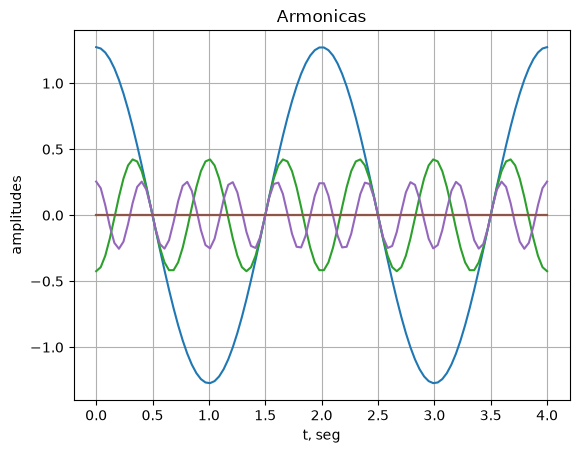

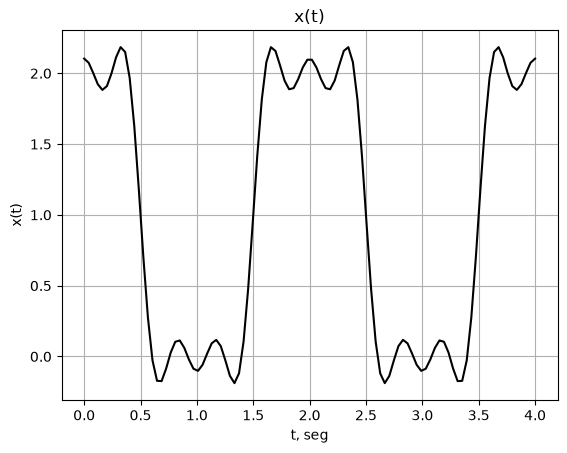

In [7]:
# Graficas para el caso I0 = 2 y T = 2
#Puede que necesite digitar dos veces shift-intro

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

fig, g = plt.subplots() 

#hay que redefinir el periodo para numpy
Tn = 2        # suponiendo que T = 2 seg
w0n = 2*np.pi/Tn
tm = np.linspace(0, 2*Tn, 100)

#redefinir las listas en sympy a numpy
a0 = a0.subs(I0, 2)
ain = [((an.subs(n, k)).subs(I0, 2)).subs(pi, np.pi) for k in range(1, m)]
bin = [((an.subs(n, k)).subs(I0, 2)).subs(pi, np.pi) for k in range(1, m)]

#para graficar las armónicas
for k in range(m-1):
    g.plot(tm, ain[k]*np.cos(w0n*(k+1)*tm))
plt.xlabel('t, seg')
plt.ylabel('amplitudes')
plt.title('Armonicas')
plt.grid(True)
plt.show()

#para graficar la señal
s = [0]*100
for k in range(m-1):
    tm = np.linspace(0, 2*Tn, 100)
    sp = (ain[k]*np.cos(w0n*(k+1)*tm))
    s += sp
s = s + a0
plt.plot(tm, s, 'k')
plt.title('x(t)')
plt.xlabel('t, seg')
plt.ylabel('x(t)')
plt.grid(True)
plt.show()

###### Serie trigonométrica de Fourier by Jose Saquimux is licensed under a Creative Commons Reconocimiento 4.0 Internacional License.